## Colab Repo Execution 
This notebook clones `mae-vae-diffusion-rag-from-scratch` in Google Colab.

In [1]:
import torch
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu | CUDA available: False


In [2]:
import os

REPO_URL = "https://github.com/RudhanLodhi/mae-vae-diffusion-rag-from-scratch.git"
REPO_DIR = "/content/mae-vae-diffusion-rag-from-scratch"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

%cd {REPO_DIR}

Cloning into '/content/mae-vae-diffusion-rag-from-scratch'...
remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 23 (delta 4), reused 20 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (23/23), 8.18 KiB | 2.04 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/mae-vae-diffusion-rag-from-scratch


In [3]:
!pip install -q -r requirements.txt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### Download UHaT Dataset

EuroSAT and BioASQ download automatically via Hugging Face `datasets`. UHaT is downloaded from Zenodo and extracted into `data/uhat/`.

In [9]:
import os

uhat_dir = "data/uhat"
if not os.path.exists(uhat_dir) or not os.listdir(uhat_dir):
    os.makedirs(uhat_dir, exist_ok=True)
    !wget -q --show-progress -O /tmp/uhat_data.zip "https://zenodo.org/records/3670611/files/data.zip?download=1"
    !unzip -q /tmp/uhat_data.zip -d {uhat_dir}
    !rm -f /tmp/uhat_data.zip
    print("UHaT extracted to", uhat_dir)
else:
    print("UHaT already present in", uhat_dir)

UHaT already present in data/uhat


### Run `check_starter.py`

In [10]:
%cd /content/mae-vae-diffusion-rag-from-scratch/scripts
!python check_starter.py
%cd /content/mae-vae-diffusion-rag-from-scratch

/content/mae-vae-diffusion-rag-from-scratch/scripts
EuroSAT train (16200, 3, 64, 64) test (5400, 3, 64, 64)
few-label subset: 160 images; patches per image: (8, 64, 192)
UHaT train (28328, 1, 28, 28) test (4747, 1, 28, 28) classes: 40
class names: ['alif', 'alif mad aa', 'ayn', 'baa', 'bari yaa', 'cheey', 'choti yaa', 'daal', 'dhaal', 'faa', 'gaaf', 'ghain', 'haa1', 'haa2', 'haa3', 'hamza', 'jeem', 'kaaf', 'khaa', 'laam', 'meem', 'noon', 'noonghunna', 'paa', 'qaaf', 'raa', 'rhraa', 'seen', 'seey', 'sheen', 'swaad', 'taa', 'ttaa', 'twa', 'waw', 'zaaa', 'zaal', 'zhaa', 'zwaa', 'zwaad']
README.md: 100% 1.76k/1.76k [00:00<00:00, 3.70MB/s]

text-corpus/test-00000-of-00001.parquet: downloading bytes:  89% 31.4M/35.3M [00:00<00:00, 49.0MB/s, 1.51MB/s  ]
text-corpus/test-00000-of-00001.parquet: downloading bytes: 100% 35.1M/35.1M [00:01<00:00, 33.5MB/s, 3.38MB/s  ]
text-corpus/test-00000-of-00001.parquet: reconstructing file: 100% 35.3M/35.3M [00:01<00:00, 33.6MB/s, 3.43MB/s  ]
Generating test

EuroSAT examples:


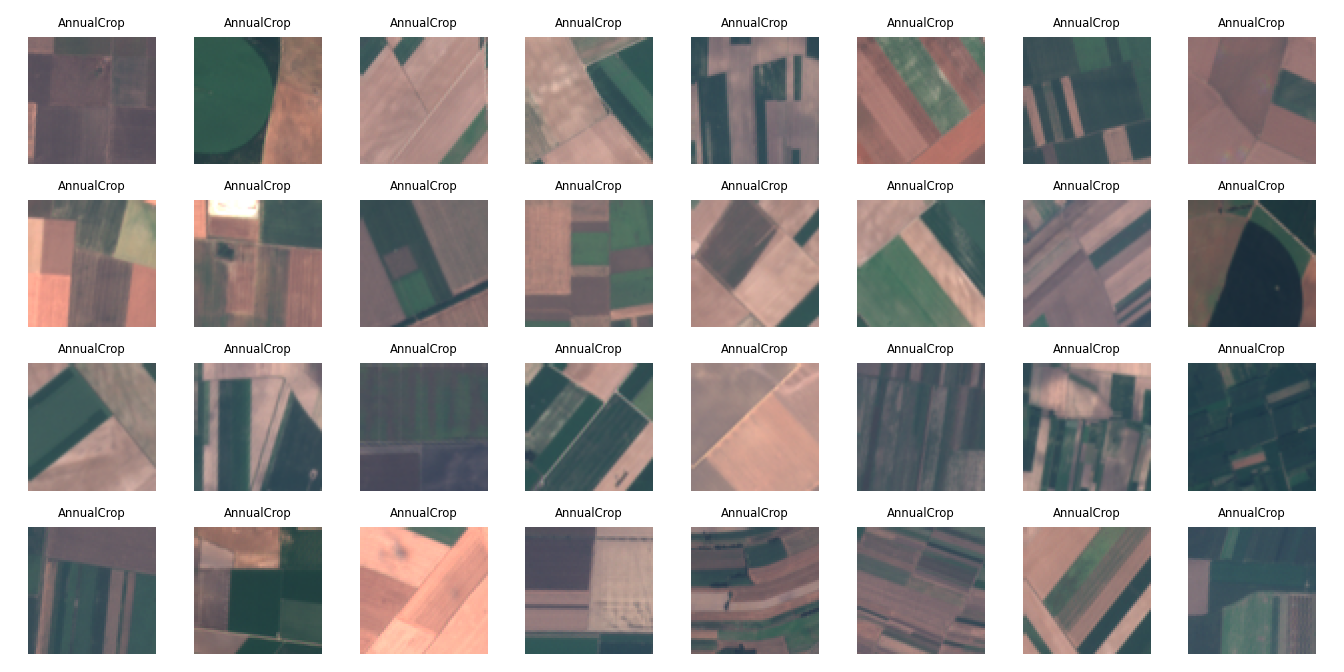

UHaT character examples:


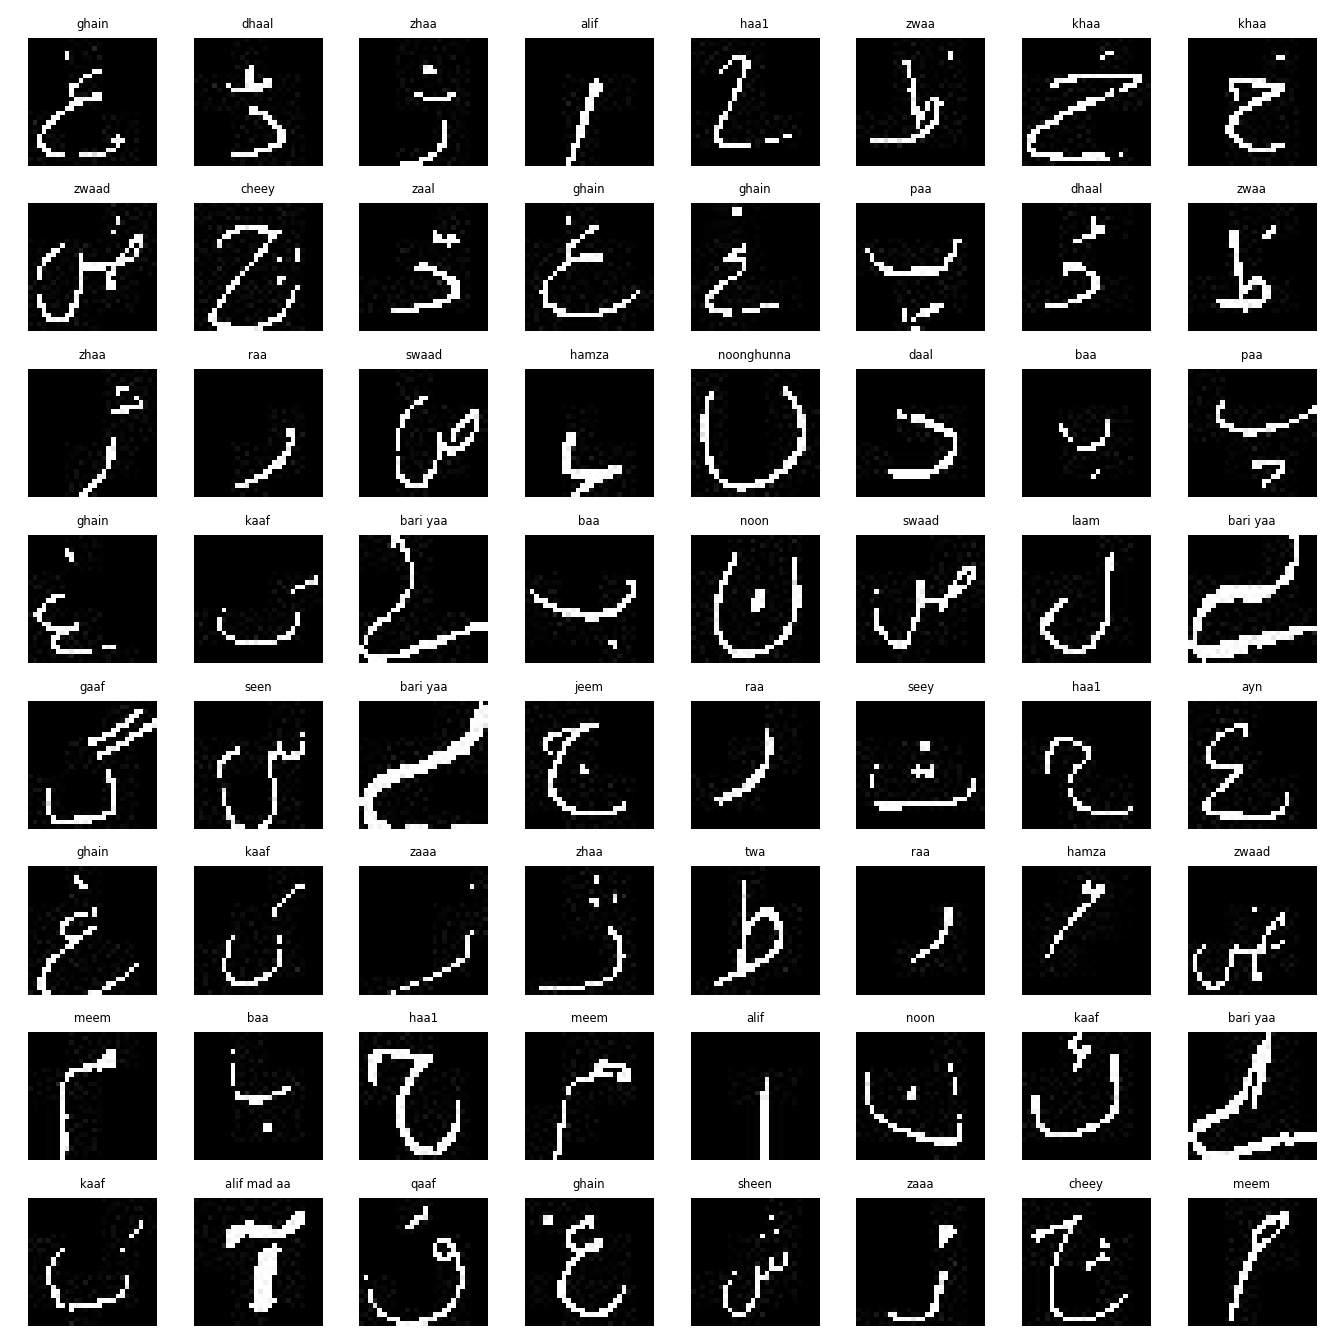

In [11]:
from IPython.display import Image, display

print("EuroSAT examples:")
display(Image("results/starter/eurosat_examples.png"))

print("UHaT character examples:")
display(Image("results/starter/uhat_examples.png"))